<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 12 - Object detection with YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab · Object detection with YOLO

So far every vision model predicted one thing per image: a class. **Object detection** asks for *every* object in the image, each with a **box**, a **class** and a **confidence score**, and the number of objects is not known in advance.

In this lab you fine-tune a pre-trained **YOLO11** detector on a small wildlife dataset with the `ultralytics` library, the standard tool for this job. The focus is practical: the label format, transfer learning with a detector, reading its metrics (precision, recall, mAP), choosing a confidence threshold, and looking at the errors.

**Contents**

1. Setup
2. The dataset and the YOLO label format
3. How a detector is judged: IoU, NMS, precision, recall and mAP
4. Baseline: the COCO-pretrained model
5. Fine-tuning YOLO on the wildlife dataset
6. Evaluation on the test set
7. Choosing the confidence threshold
8. Looking at the predictions
9. Using the model on new images
10. Summary and practical tips

Theory: Part C of the slides [CNNs, transfer learning, segmentation, detection](https://imagra93.github.io/ML-course-labs/slides/neural_networks/04_cnn.html) (object detection, YOLO, NMS, mAP). IoU, NMS and mAP written from scratch, and how the YOLO head works inside, are in the **extended version** of this lab, linked at the end.

**Use a GPU** (in Colab: *Runtime → Change runtime type → T4 GPU*). With it the lab takes about 5 minutes. On a CPU the settings are reduced automatically (section 5) and it takes 15 to 20 minutes.

## 1. Setup

Colab does not include `ultralytics`, so the first cell installs it if it is missing.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("ultralytics") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)

In [2]:
import io, time, urllib.request, zipfile
from pathlib import Path
from IPython.display import display, Image as ImageDisplay
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import torch
from ultralytics import YOLO

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

def show_photos(fig):
    """Show a figure of photos as JPEG: about 10 times lighter than PNG in the saved notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=90, bbox_inches="tight", pil_kwargs={"quality": 85}); plt.close(fig)
    display(ImageDisplay(buf.getvalue()))

device: NVIDIA GeForce RTX 3090


## 2. The dataset and the YOLO label format

The *African Wildlife* dataset (Ultralytics, about 100 MB) has 1,504 photos with 4 classes: buffalo, elephant, rhino and zebra. It comes in the folder layout that YOLO expects:

```
african-wildlife/
├── images/{train,val,test}/xxx.jpg
└── labels/{train,val,test}/xxx.txt     ← one text file per image, same name
```

A small `data.yaml` file tells YOLO where the splits are and what the class names are. This is all you need to train on **your own** data too: images, one label file per image, and a `data.yaml`.

In [3]:
DATA_ROOT = Path("data/african-wildlife")
URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip"
if not (DATA_ROOT / "images").exists():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_ROOT.parent / "african-wildlife.zip"
    print("downloading", URL); urllib.request.urlretrieve(URL, zip_path)
    zipfile.ZipFile(zip_path).extractall(DATA_ROOT); zip_path.unlink()

CLASSES = ["buffalo", "elephant", "rhino", "zebra"]
COLORS = ["#8c564b", "#1f77b4", "#7f7f7f", "#d62728"]
DATA_YAML = DATA_ROOT / "data.yaml"
DATA_YAML.write_text(f"path: {DATA_ROOT.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                     "names:\n" + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
print(DATA_YAML.read_text())

def images(split):
    return sorted(p for p in (DATA_ROOT / "images" / split).iterdir() if p.suffix.lower() == ".jpg")

for split in ("train", "val", "test"):
    print(f"{split:<6}{len(images(split)):5d} images")

p = images("train")[0]
print(f"\nlabel file of {p.name}:")
print((DATA_ROOT / "labels/train" / f"{p.stem}.txt").read_text())

path: /content/data/african-wildlife
train: images/train
val: images/val
test: images/test
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra
train  1052 images
val     225 images
test    227 images
label file of 1 (10).jpg:
0 0.410000 0.408750 0.400000 0.382500


Each line of a label file is one object: `class x_centre y_centre width height`. The four coordinates are **divided by the image width and height**, so they lie in $[0, 1]$ and survive any resizing of the image. To draw a box we convert it to pixel corners $(x_1, y_1, x_2, y_2)$: $x_1 = (x_c - w/2)\,W$, $x_2 = (x_c + w/2)\,W$, and the same for $y$ with the height $H$. The origin is the **top-left** corner, with $y$ pointing down.

objects per class in the training set: {'buffalo': 399, 'elephant': 558, 'rhino': 399, 'zebra': 575}


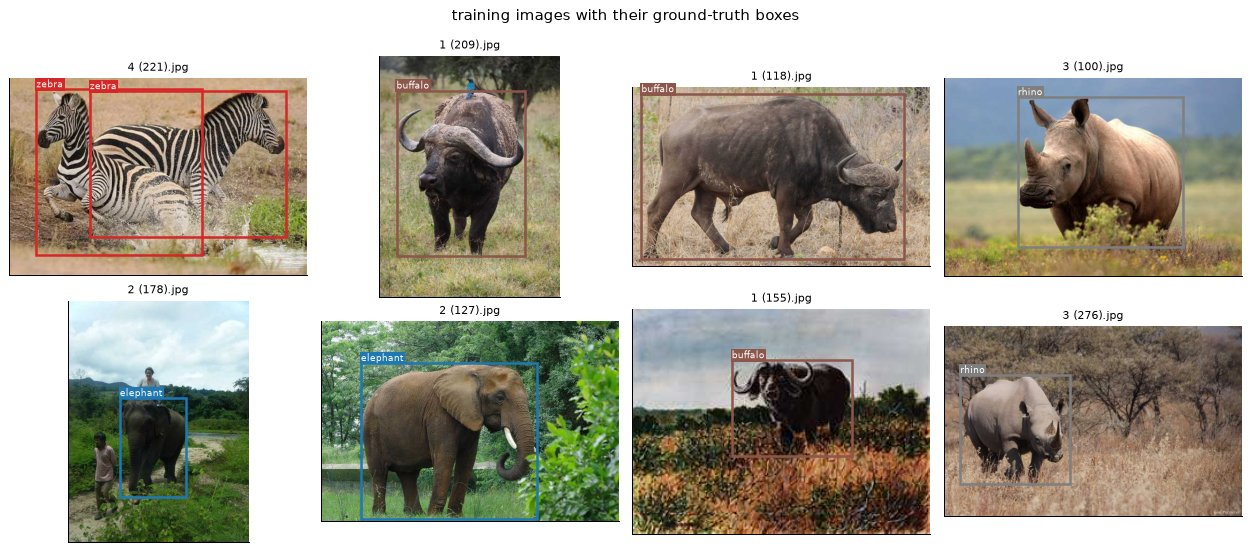

In [4]:
def load(img_path):
    return np.asarray(Image.open(img_path).convert("RGB"))

def read_labels(img_path):
    """YOLO label file -> class ids (k,) and boxes (k, 4) as normalised (x_centre, y_centre, w, h)."""
    lbl = DATA_ROOT / "labels" / Path(img_path).parent.name / f"{Path(img_path).stem}.txt"
    a = np.loadtxt(lbl, ndmin=2) if lbl.exists() and lbl.stat().st_size else np.zeros((0, 5))
    return a[:, 0].astype(int), a[:, 1:]

def xywhn_to_xyxy(b, W, H):
    xc, yc, w, h = np.asarray(b, float).reshape(-1, 4).T
    return np.stack([(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H], axis=1)

def draw(ax, img, boxes, texts, colors, dashed=False, title=None):
    """Draw xyxy boxes, with a text label on top of each one."""
    ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for (x1, y1, x2, y2), text, col in zip(boxes, texts, colors):
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, ec=col, ls="--" if dashed else "-"))
        if text:
            ax.text(x1, y1, text, color="white", fontsize=7, va="bottom", bbox=dict(fc=col, ec="none", pad=1))
    if title: ax.set_title(title, fontsize=9)

def draw_gt(ax, p, dashed=False, title=None, show_text=True):
    img = load(p); cls, xywhn = read_labels(p)
    draw(ax, img, xywhn_to_xyxy(xywhn, img.shape[1], img.shape[0]),
         [CLASSES[c] if show_text else "" for c in cls], [COLORS[c] for c in cls], dashed, title)

counts = np.zeros(4, int)
for p in images("train"):
    counts += np.bincount(read_labels(p)[0], minlength=4)
print("objects per class in the training set:", dict(zip(CLASSES, counts.tolist())))

fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
for ax, p in zip(axes.ravel(), rng.choice(images("train"), 8, replace=False)):
    draw_gt(ax, p, title=p.name)
plt.suptitle("training images with their ground-truth boxes"); plt.tight_layout(); show_photos(fig)

## 3. How a detector is judged: IoU, NMS, precision, recall and mAP

A few ideas are enough to read everything that YOLO prints.

**IoU (Intersection over Union)** measures how well a predicted box $A$ matches a true box $B$:

$$
\text{IoU}(A, B) = \frac{\text{area}(A \cap B)}{\text{area}(A \cup B)} \in [0, 1] .
$$

1 means identical boxes, 0 means no overlap. A prediction counts as **correct** (a *true positive*) if it has the right class and an IoU of at least 0.5 with a true box that no other prediction has already claimed. Otherwise it is a **false positive**. True boxes that no prediction matches are **false negatives** (missed objects).

**What YOLO predicts.** The network looks at the image once and makes a guess at every cell of three grids, about 8,400 candidate boxes for a $640 \times 640$ image, each with a score per class. Two steps turn them into a clean list:
1. a **confidence threshold** drops the candidates with a low score;
2. **non-maximum suppression (NMS)** removes duplicates: keep the best-scoring box, delete the other boxes of the same class that overlap it too much (IoU above 0.7), and repeat.

**Precision and recall**, as in the classification labs: precision $= TP/(TP + FP)$ is the fraction of the predicted boxes that are right, recall $= TP/(TP + FN)$ the fraction of the animals that were found. A lower confidence threshold finds more animals (higher recall) but also more false alarms (lower precision).

**mAP** sums up that trade-off in one number. For each class, the **average precision (AP)** is the area under the precision–recall curve obtained by moving the threshold from high to low; mAP is the mean over the classes:
- **mAP50**: a box counts as correct from IoU 0.5;
- **mAP50-95**: the average over the IoU thresholds $0.50, 0.55, \dots, 0.95$, which also rewards *precise* boxes. It is always lower, and it is the main metric of the COCO benchmark.

## 4. Baseline: the COCO-pretrained model

`YOLO("yolo11n.pt")` downloads YOLO11n (*nano*, 2.6 million parameters) pre-trained on **COCO**, a dataset with 80 everyday classes. Two of our four classes are among them (**elephant** and **zebra**); **buffalo** and **rhino** are not. What does it predict before any training?

80 COCO classes, for example: ['person', 'car', 'dog', 'cow', 'elephant', 'zebra']


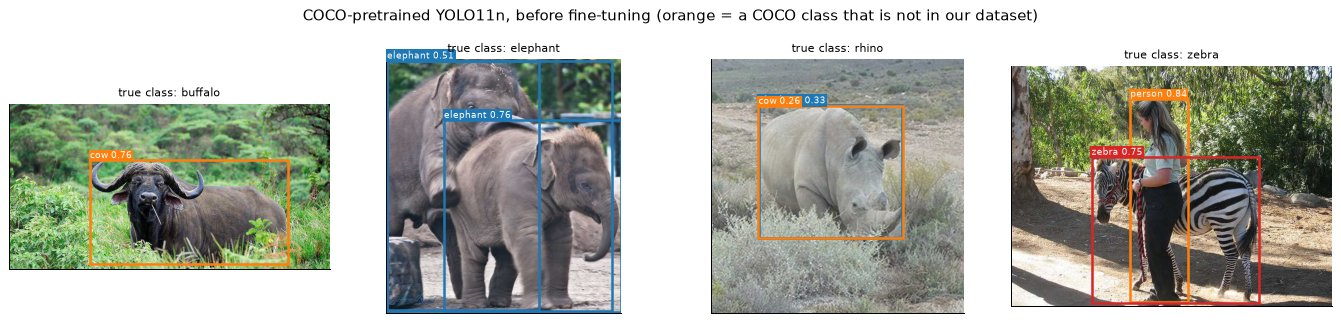

In [5]:
coco = YOLO("yolo11n.pt")
print(len(coco.names), "COCO classes, for example:", [coco.names[i] for i in (0, 2, 16, 19, 20, 22)])

examples = [next(p for p in images("val") if p.name.startswith(f"{c + 1} (") and set(read_labels(p)[0]) == {c})
            for c in range(4)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, p in zip(axes, examples):
    r = coco.predict(str(p), conf=0.25, verbose=False)[0].cpu()
    names = [coco.names[int(c)] for c in r.boxes.cls]
    cols = [COLORS[CLASSES.index(n)] if n in CLASSES else "#ff7f0e" for n in names]
    draw(ax, load(p), r.boxes.xyxy.numpy(), [f"{n} {s:.2f}" for n, s in zip(names, r.boxes.conf)], cols,
         title=f"true class: {CLASSES[read_labels(p)[0][0]]}")
plt.suptitle("COCO-pretrained YOLO11n, before fine-tuning (orange = a COCO class that is not in our dataset)")
plt.tight_layout(); show_photos(fig)

Without any training on this dataset, the model already finds every animal and puts a sensible box around it. It names the elephants and the zebra correctly, and even finds a person that our dataset does not label. It calls the buffalo a **cow**, the closest COCO class, and is unsure about the rhino (*cow* 0.26, *elephant* 0.33). The backbone and the box regression already work; what is missing are the class names. That is why fine-tuning on about a thousand images takes only a few minutes.

## 5. Fine-tuning YOLO on the wildlife dataset

`model.train(data=...)` does transfer learning, as in Lab 11 with the ResNet: it keeps the pre-trained backbone, replaces the last layers of the head with new ones for our 4 classes, and fine-tunes everything. The main arguments:

| Argument | Meaning | Here |
|---|---|---|
| `data` | the `data.yaml` file | |
| `epochs` | passes over the training set | 20 on a GPU, 8 on a CPU |
| `imgsz` | images are resized (keeping the aspect ratio, with padding) to `imgsz × imgsz` | 640 on a GPU, 320 on a CPU |
| `batch` | images per step | 16 |
| `patience` | **early stopping**: stop after this many epochs without improvement on the validation set | 10 |
| `freeze` | number of initial layers to freeze (feature extraction) | 0: fine-tune everything |

Ultralytics applies the same two **early-stopping** techniques as our `fit` function in Labs 10 and 11. After every epoch it evaluates the model on the validation split and saves the weights of the best epoch as `best.pt`, and `patience` stops the run when the validation score stops improving.

**Augmentation is done for you**, and it is strong: colour changes, horizontal flips, rescaling and shifts, and **mosaic**, which tiles 4 training images into one. In detection, every geometric augmentation must move the **boxes** together with the pixels; Ultralytics does both. Mosaic is switched off for the last 10 epochs, so that the model finishes on images that look like the test images.

In [6]:
EPOCHS, IMGSZ = (20, 640) if DEVICE == 0 else (8, 320)
model = YOLO("yolo11n.pt")
t0 = time.time()
model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=16, patience=10, device=DEVICE, workers=4,
            seed=0, project=str(Path("runs").resolve()), name="wildlife", exist_ok=True, plots=True, verbose=False)
RUN_DIR = Path(model.trainer.save_dir)
print(f"\ntraining took {(time.time() - t0) / 60:.1f} min; weights and plots in {RUN_DIR}")

...
Validating /content/runs/wildlife/weights/best.pt...
Ultralytics 8.4.175 🚀 Python-3.12.2 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all        225        379      0.953      0.887      0.952       0.79
Speed: 0.5ms preprocess, 2.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/wildlife
training took 2.3 min; weights and plots in /content/runs/wildlife


The log ends with the validation results of `best.pt`, per class. The training history is saved in `results.csv`: the three parts of the loss (box position, class, and a box-refinement term called DFL) and the validation mAP after every epoch.

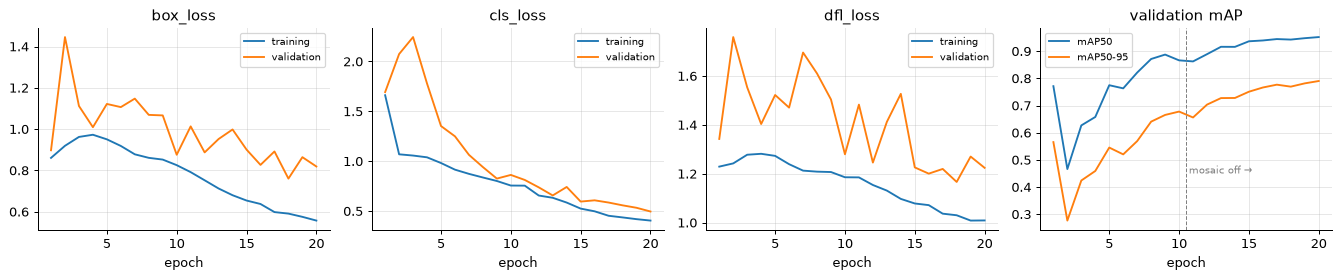

In [7]:
hist = pd.read_csv(RUN_DIR / "results.csv"); hist.columns = hist.columns.str.strip()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, name in zip(axes, ["box_loss", "cls_loss", "dfl_loss"]):
    ax.plot(hist.epoch, hist[f"train/{name}"], label="training"); ax.plot(hist.epoch, hist[f"val/{name}"], label="validation")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
axes[3].plot(hist.epoch, hist["metrics/mAP50(B)"], label="mAP50"); axes[3].plot(hist.epoch, hist["metrics/mAP50-95(B)"], label="mAP50-95")
axes[3].axvline(EPOCHS - 10 + 0.5, c="gray", lw=0.8, ls="--"); axes[3].text(EPOCHS - 10 + 0.7, 0.45, "mosaic off →", fontsize=8, c="gray")
axes[3].set_title("validation mAP"); axes[3].set_xlabel("epoch"); axes[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

What to read in these curves:
- **The pre-trained start.** After one epoch the validation mAP50 is already about 0.77: the features and the box regression transfer from COCO, and only the new 4-class output layer starts from scratch. (It drops at epoch 2, while the learning rate warms up and the new layer is still poor, and then recovers.)
- **Training and validation losses are not directly comparable.** The training loss is measured on augmented mosaics, the validation loss on plain images.
- **Not converged.** The validation mAP50-95 is still rising at the last epoch, so `patience` never stopped the run, and more epochs would help (exercise 1).

## 6. Evaluation on the test set

The validation split was used to choose `best.pt`, so the honest estimate comes from the untouched **test** split. `model.val(split="test")` computes everything at once.

In [8]:
best = YOLO(RUN_DIR / "weights" / "best.pt")
metrics = best.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=16, device=DEVICE, verbose=False,
                   project=str(Path("runs").resolve()), name="wildlife_test", exist_ok=True)
table = pd.DataFrame({"precision": metrics.box.p, "recall": metrics.box.r, "AP50": metrics.box.ap50, "AP50-95": metrics.box.ap},
                     index=[CLASSES[i] for i in metrics.box.ap_class_index])
table.loc["mean"] = table.mean()
print(table.round(3))

Ultralytics 8.4.175 🚀 Python-3.12.2 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3090, 24253MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 890.6±515.6 MB/s, size: 53.5 KB)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all        227        375      0.957      0.931      0.979      0.826
Speed: 1.0ms preprocess, 4.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/wildlife_test
          precision  recall   AP50  AP50-95
buffalo       0.952   0.909  0.983    0.858
elephant      0.969   0.945  0.971    0.787
rhino         0.973   0.944  0.990    0.891
zebra         0.933   0.926  0.971    0.766
mean          0.957   0.931  0.979    0.826


On the 227 test images: **mAP50 = 0.98** and **mAP50-95 = 0.83**. At the confidence threshold with the best $F_1$, which is where Ultralytics reports precision and recall, 96% of the predicted boxes are correct and 93% of the animals are found. mAP50-95 is lower because it also demands tight boxes: zebras and elephants, often in overlapping herds, are the hardest to box precisely.

## 7. Choosing the confidence threshold

mAP averages over all confidence thresholds, but an application must commit to **one**: below it, a box is not shown. `val()` also saves precision, recall and their combination $F_1 = 2PR/(P + R)$ as functions of the threshold:

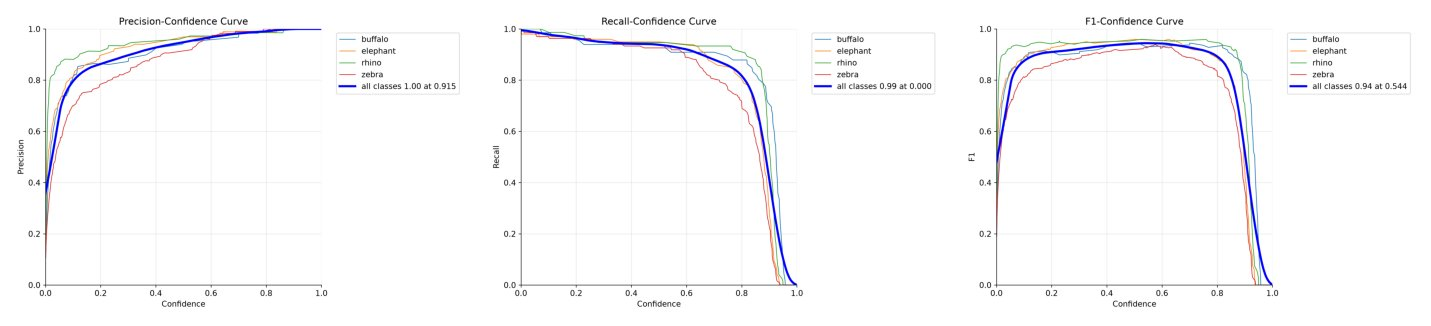

In [9]:
def saved_plot(name):
    """A plot saved by val() (recent Ultralytics versions prefix the file names with 'Box')."""
    d = Path(metrics.save_dir)
    return plt.imread(d / f"Box{name}" if (d / f"Box{name}").exists() else d / name)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, name in zip(axes, ["P_curve.png", "R_curve.png", "F1_curve.png"]):
    ax.imshow(saved_plot(name)); ax.axis("off")
plt.tight_layout(); show_photos(fig)

Lowering the threshold finds more animals (recall, middle) but lets in more false alarms (precision, left). $F_1$ is highest, 0.94, at a confidence of about 0.54, and it is almost flat between about 0.2 and 0.8: within that range, choose according to what the application can tolerate. The zebras (red) have the lowest curves.

## 8. Looking at the predictions

Metrics hide *what* goes wrong. Below, test images with the ground truth dashed and the predictions solid, at a confidence threshold of 0.4. The first row is random; the second shows other images where something went wrong: a missed animal, a wrong class or an extra box.

36 of 227 test images have at least one error at conf = 0.4


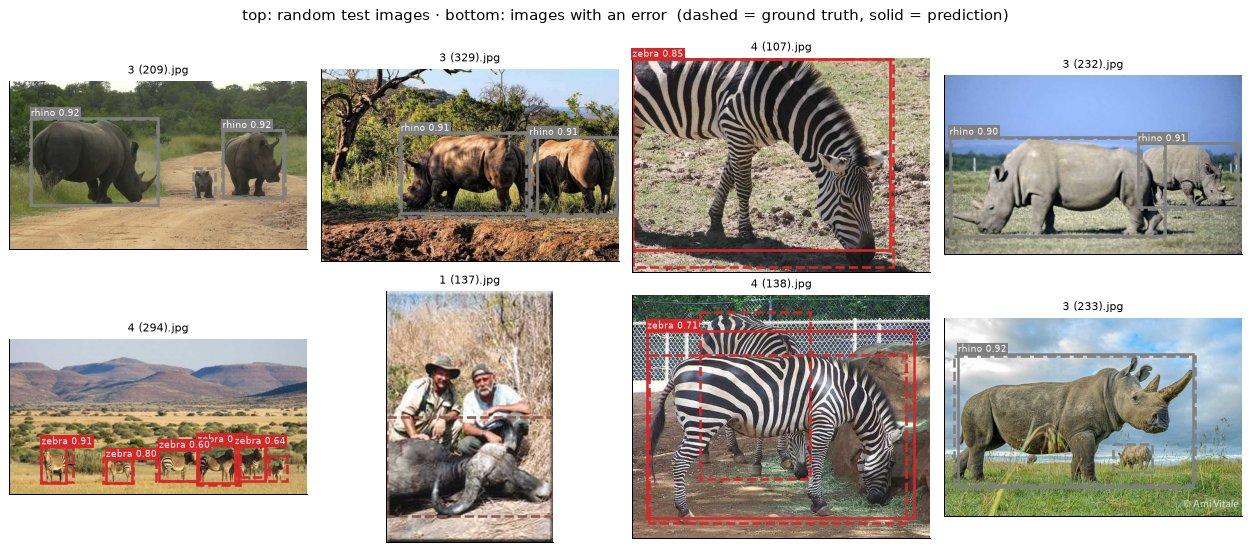

In [10]:
CONF = 0.4

def errors_in(p, r, iou_thr=0.5):
    """True if the predictions r on image p miss an animal or contain a box that matches no animal."""
    cls, xywhn = read_labels(p); gt = xywhn_to_xyxy(xywhn, *r.orig_shape[::-1])
    pb, pc = r.boxes.xyxy.numpy(), r.boxes.cls.numpy().astype(int)
    if len(pb) != len(gt):
        return True
    for b, c in zip(pb, pc):
        iw = np.clip(np.minimum(b[2], gt[:, 2]) - np.maximum(b[0], gt[:, 0]), 0, None)
        ih = np.clip(np.minimum(b[3], gt[:, 3]) - np.maximum(b[1], gt[:, 1]), 0, None)
        inter = iw * ih
        iou = inter / ((b[2] - b[0]) * (b[3] - b[1]) + (gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1]) - inter)
        if not np.any((iou >= iou_thr) & (cls == c)):
            return True
    return False

test_imgs = images("test")
results = {p: best.predict(str(p), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0].cpu() for p in test_imgs}
wrong = [p for p in test_imgs if errors_in(p, results[p])]
print(f"{len(wrong)} of {len(test_imgs)} test images have at least one error at conf = {CONF}")

def show_predictions(ax, p):
    r = results[p]; pc = r.boxes.cls.numpy().astype(int)
    draw_gt(ax, p, dashed=True, show_text=False)
    draw(ax, load(p), r.boxes.xyxy.numpy(), [f"{CLASSES[c]} {s:.2f}" for c, s in zip(pc, r.boxes.conf)],
         [COLORS[c] for c in pc], title=p.name)

fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
top_row = list(rng.choice(test_imgs, 4, replace=False))
for ax, p in zip(axes[0], top_row):
    show_predictions(ax, p)
for ax, p in zip(axes[1], rng.choice([p for p in wrong if p not in top_row], 4, replace=False)):
    show_predictions(ax, p)
plt.suptitle("top: random test images · bottom: images with an error  (dashed = ground truth, solid = prediction)")
plt.tight_layout(); show_photos(fig)

Most errors fall into a few families, all visible above:
- **Small or distant animals**: a calf between two adult rhinos, a rhino far in the background, the zebras of a distant herd. Few pixels means low scores.
- **Crowds**: overlapping animals of the same class produce merged boxes or extra ones.
- **Unusual views**: a buffalo lying on the ground is missed.
- **Annotation choices**: some "false positives" are animals the annotator did not label, such as a partly visible animal at the border of the photo.

## 9. Using the model on new images

`predict` accepts a file path, a URL, a folder, a NumPy array or a video. Each result holds the boxes in several formats (`xyxy`, `xywhn`...), the scores and the classes, and `plot()` draws them. To use the model in another program, keep `best.pt`: `YOLO("best.pt")` loads it again.

buffalo   score 0.97   box (x1, y1, x2, y2) = [30, 75, 315, 504]
buffalo   score 0.93   box (x1, y1, x2, y2) = [485, 77, 800, 489]
buffalo   score 0.90   box (x1, y1, x2, y2) = [292, 119, 488, 465]


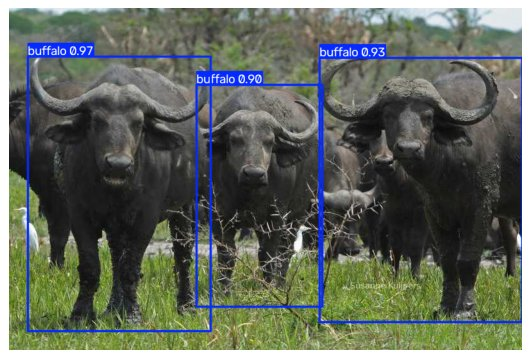

In [11]:
p_new = next(p for p in test_imgs if p not in wrong and len(read_labels(p)[0]) >= 3)    # a test image with 3+ animals
r = best.predict(str(p_new), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0].cpu()
for box, s, c in zip(r.boxes.xyxy.numpy(), r.boxes.conf.numpy(), r.boxes.cls.numpy().astype(int)):
    print(f"{CLASSES[c]:<9} score {s:.2f}   box (x1, y1, x2, y2) = {box.round(0).astype(int).tolist()}")
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(r.plot()[:, :, ::-1]); ax.axis("off")                 # plot() returns a BGR image (OpenCV order)
plt.tight_layout(); show_photos(fig)

## 10. Summary and practical tips

- Detection outputs a **set** of (box, class, score) triples of unknown size. YOLO predicts candidate boxes at every cell of three grids in one pass, then removes low scores (**confidence threshold**) and duplicates (**NMS**).
- A prediction is correct when it has the right class and an **IoU** of at least 0.5 with a true box. **Precision** and **recall** depend on the confidence threshold; **mAP50** and **mAP50-95** summarise all thresholds.
- Fine-tuning a COCO-pretrained model on about a thousand labelled images takes a few minutes, because the backbone and the box regression transfer; only the class names are new.

**Tips for your own detector:**
- **Labels are the work.** Draw boxes with a tool such as [Label Studio](https://labelstud.io), [CVAT](https://www.cvat.ai) or [Roboflow](https://roboflow.com), export in YOLO format, and write a `data.yaml`. A few hundred well-labelled images per class already go a long way.
- **Always start from pre-trained weights** (`yolo11n.pt`, or `yolo11s.pt` / `yolo11m.pt` for more accuracy at a higher cost).
- **`imgsz`**: small objects need pixels. If your objects are small in the image, do not go below 640.
- **Watch the validation mAP** in `results.csv`: if it is still rising at the last epoch, train longer; `patience` and `best.pt` protect you from training too long.
- **Choose the confidence threshold for the application**: low when a missed object is expensive (safety), high when false alarms are expensive.
- **Look at the errors**, not only at mAP. Some "errors" are mistakes in the labels.

## Exercises

Try each one before opening the answer.

1. **Longer training.** Train for 50 epochs instead of 20. How much do mAP50 and mAP50-95 improve on the test set? Which of the two improves more, and why?
2. **Feature extraction.** Train with `freeze=10`, which freezes the backbone. Is the result worse than full fine-tuning? Which classes suffer most: the ones COCO knows (elephant, zebra) or the new ones?
3. **Threshold.** A park ranger wants an alert whenever a rhino appears in a camera trap. Would you use a confidence threshold of 0.25 or 0.8? And for an automatic census that counts the animals in thousands of photos?

<details>
<summary><b>Answers</b></summary>

**1.** Both improve a little, mAP50-95 more than mAP50. With 20 epochs, the model already finds almost every animal at IoU 0.5, so mAP50 has little room left. The extra epochs mostly make the boxes tighter, which only the strict IoU thresholds of mAP50-95 reward. (The validation mAP50-95 curve was still rising at the end of section 5.)

**2.** Usually a few points worse: the frozen backbone cannot adapt its features to these photos. The new classes (buffalo, rhino) tend to suffer most, because the frozen features were never trained to tell them apart, while COCO already contains elephants and zebras. The frozen model trains faster and needs less memory, which matters for big models and small datasets.

**3.** For the ranger, a **low** threshold (0.25): a missed rhino is much worse than a false alarm that a person can dismiss in a second, so recall matters most. For the census, a **higher** threshold (around the maximum of the F1 curve, or above): every false positive adds an animal that does not exist, and with thousands of photos nobody checks them one by one. In both cases, choose the threshold on the validation set, not on the test set.

</details>

## Going further: the extended lab

The extended version of this lab trains the same model and adds what happens inside:
- box formats and **IoU** from scratch (checked against `torchvision`), GIoU and how strict IoU = 0.5 really is;
- how the YOLO11 head works: grids and strides, anchor-free boxes, the 16-bin distance distributions (DFL);
- the training targets and the three-term loss;
- **NMS** and **mAP** written from scratch and checked against Ultralytics;
- label errors in the dataset, typical failure modes, speed, and export to **ONNX**; and six projects to try.

<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 12 - Object detection with YOLO - extended.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> [lab 12 - Object detection with YOLO - extended.ipynb](lab%2012%20-%20Object%20detection%20with%20YOLO%20-%20extended.ipynb)